# Task 3: Linear Regression

Implementing simple and multiple linear regression to predict house prices using the Housing dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Housing.csv")

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [2]:
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (545, 13)

Data types:
price               int64
area                int64
bedrooms            int64
bathrooms           int64
stories             int64
mainroad              str
guestroom             str
basement              str
hotwaterheating       str
airconditioning       str
parking             int64
prefarea              str
furnishingstatus      str
dtype: object

Missing values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate rows: 0


In [3]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [4]:
categorical_cols = df.select_dtypes(include="str").columns

print("Categorical columns:")
print(categorical_cols.tolist())

Categorical columns:
['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [5]:
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())


mainroad:
<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str

guestroom:
<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str

basement:
<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str

hotwaterheating:
<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str

airconditioning:
<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str

prefarea:
<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str

furnishingstatus:
<ArrowStringArray>
['furnished', 'semi-furnished', 'unfurnished']
Length: 3, dtype: str


In [6]:
df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

df_encoded.head()

,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,2,1,0,0,0,1,1,0,0
1,12250000,8960,4,4,4,3,1,0,0,0,1,0,0,0
2,12250000,9960,3,2,2,2,1,0,1,0,0,1,1,0
3,12215000,7500,4,2,2,3,1,0,1,0,1,1,0,0
4,11410000,7420,4,1,2,2,1,1,1,0,1,0,0,0


In [7]:
print("Updated shape:", df_encoded.shape)

print("\nUpdated columns:")
print(df_encoded.columns.tolist())

print("\nData types:")
print(df_encoded.dtypes)

Updated shape: (545, 14)

Updated columns:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'mainroad_yes', 'guestroom_yes', 'basement_yes', 'hotwaterheating_yes', 'airconditioning_yes', 'prefarea_yes', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']

Data types:
price                              int64
area                               int64
bedrooms                           int64
bathrooms                          int64
stories                            int64
parking                            int64
mainroad_yes                       int64
guestroom_yes                      int64
basement_yes                       int64
hotwaterheating_yes                int64
airconditioning_yes                int64
prefarea_yes                       int64
furnishingstatus_semi-furnished    int64
furnishingstatus_unfurnished       int64
dtype: object


In [8]:
X = df_encoded.drop("price", axis=1)
y = df_encoded["price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Features shape: (545, 13)
Target shape: (545,)

Features:
['area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'mainroad_yes', 'guestroom_yes', 'basement_yes', 'hotwaterheating_yes', 'airconditioning_yes', 'prefarea_yes', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [10]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (436, 13)
X_test shape: (109, 13)
y_train shape: (436,)
y_test shape: (109,)


## Simple Linear Regression

First, a simple linear regression model is built using `area` as the single predictor to understand the relationship between house area and price.

In [11]:
from sklearn.linear_model import LinearRegression

X_simple = df[["area"]]
y_simple = df["price"]

X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple,
    y_simple,
    test_size=0.2,
    random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train_simple)

y_pred_simple = simple_model.predict(X_test_simple)

print("Coefficient:", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)

Coefficient: 425.72984193878284
Intercept: 2512254.2639593435


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_simple = mean_absolute_error(y_test_simple, y_pred_simple)
mse_simple = mean_squared_error(y_test_simple, y_pred_simple)
r2_simple = r2_score(y_test_simple, y_pred_simple)

print("Simple Linear Regression Performance")
print("MAE:", mae_simple)
print("MSE:", mse_simple)
print("R²:", r2_simple)

Simple Linear Regression Performance
MAE: 1474748.1337969352
MSE: 3675286604768.185
R²: 0.27287851871974644


In [13]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)
y_pred_multiple = multiple_model.predict(X_test)

print("Multiple Linear Regression model trained successfully.")

Multiple Linear Regression model trained successfully.


In [14]:
mae_multiple = mean_absolute_error(y_test, y_pred_multiple)
mse_multiple = mean_squared_error(y_test, y_pred_multiple)
r2_multiple = r2_score(y_test, y_pred_multiple)

print("Multiple Linear Regression Performance")
print("MAE:", mae_multiple)
print("MSE:", mse_multiple)
print("R²:", r2_multiple)

Multiple Linear Regression Performance
MAE: 970043.4039201637
MSE: 1754318687330.6643
R²: 0.6529242642153184


## Simple vs Multiple Linear Regression

Multiple Linear Regression performs better than Simple Linear Regression on the test data. It has a lower MAE and MSE and a higher R² score, indicating that using multiple house features provides a better fit for predicting house prices than using area alone.

## Regression Line

The regression line shows the relationship between house area and price using the simple linear regression model.

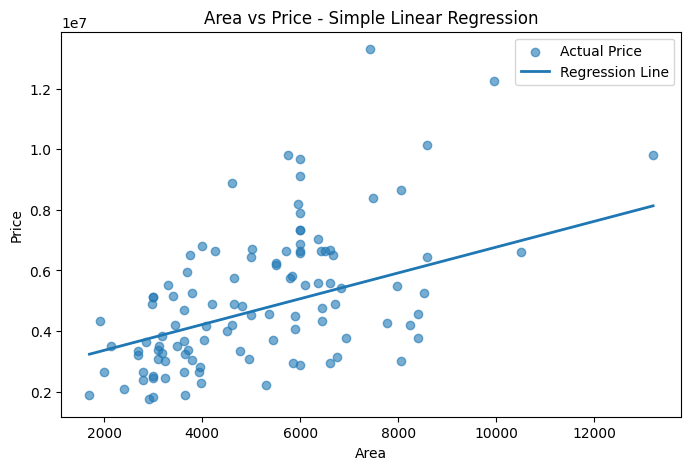

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test_simple["area"],
    y_test_simple,
    alpha=0.6,
    label="Actual Price"
)

sorted_indices = X_test_simple["area"].argsort()

plt.plot(
    X_test_simple["area"].iloc[sorted_indices],
    y_pred_simple[sorted_indices],
    linewidth=2,
    label="Regression Line"
)

plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Area vs Price - Simple Linear Regression")
plt.legend()
plt.show()

### Interpretation

The regression line shows a positive relationship between area and house price. As the area increases, the predicted house price also increases. However, the actual prices are widely scattered around the regression line, which indicates that area alone does not explain house prices very well. This is consistent with the R² value of 0.2729 from the simple linear regression model.

In [16]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": multiple_model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

coefficients

,Feature,Coefficient
2,bathrooms,1.094445e+06
9,airconditioning_yes,7.914267e+05
8,hotwaterheating_yes,6.846499e+05
10,prefarea_yes,6.298906e+05
3,stories,4.074766e+05
7,basement_yes,3.902512e+05
5,mainroad_yes,3.679199e+05
6,guestroom_yes,2.316100e+05
4,parking,2.248419e+05
1,bedrooms,7.677870e+04


In [17]:
print("Intercept:", multiple_model.intercept_)

Intercept: 260032.35760741215


In [18]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred_multiple
})

comparison.head(10)

,Actual Price,Predicted Price
0,4060000,5.164654e+06
1,6650000,7.224722e+06
2,3710000,3.109863e+06
3,6440000,4.612075e+06
4,2800000,3.294646e+06
5,4900000,3.532275e+06
6,5250000,5.611775e+06
7,4543000,6.368146e+06
8,2450000,2.722857e+06
9,3353000,2.629406e+06


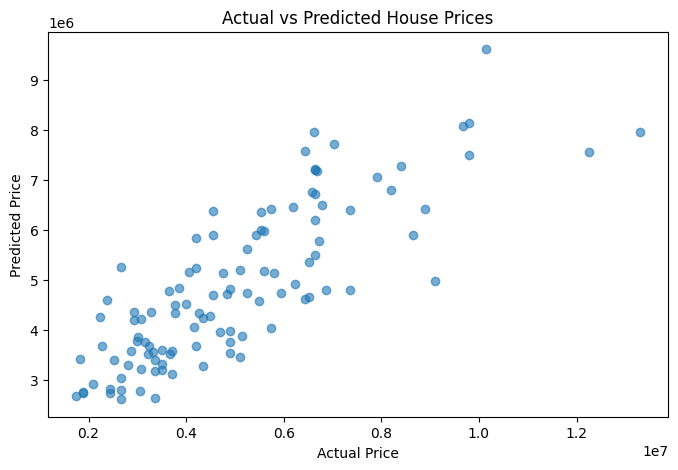

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_multiple, alpha=0.6)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

### Interpretation

The Actual vs Predicted plot shows a positive relationship between actual and predicted house prices. Most predictions follow the overall trend of the actual prices, although there is some deviation between them. This indicates that the multiple linear regression model captures a substantial part of the relationship between the input features and house prices, consistent with the test R² score of 0.6529.

## Conclusion

Simple Linear Regression using area alone achieved an R² of 0.2729. Multiple Linear Regression using the available house features performed better, achieving an R² of 0.6529 with lower MAE and MSE. This shows that using multiple features provides better predictive performance than using area alone for house price prediction.